<img src="images/nvidia_header.png" style="margin-left: -30px; width: 300px; float: left;">

# Accelerating Clustering Algorithms to Achieve the Highest Performance #

## Part 1: UMAP ##

**Table of Contents**
<br>
This notebook shows how to perform UMAP for dimensionality reduction. This notebook covers the below sections: 

1. [Initial Envrionment Set Up](#Initial-Envrionment-Set-Up)
2. [CPU UMAP](#CPU-UMAP)
3. [GPU UMAP](#GPU-UMAP)

## Initial Envrionment Set Up

In [1]:
%load_ext cudf.pandas

In [2]:
import pandas as pd
# Sample operation
cudf_df = pd.DataFrame({'a': [1, 2, 3], 'b': [4, 5, 6]})
cudf_df.info()

<class 'cudf.core.dataframe.DataFrame'>
RangeIndex: 3 entries, 0 to 2
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype
---  ------  --------------  -----
 0   a       3 non-null      int64
 1   b       3 non-null      int64
dtypes: int64(2)
memory usage: 48.0 bytes


In [3]:
import cupy as cp
# Sample operation
guess_ages = cp.zeros((2,3))
type(guess_ages)

cupy.ndarray

## CPU UMAP

In [4]:
import warnings

# Suppress FutureWarning for 'force_all_finite'
warnings.filterwarnings("ignore", category=FutureWarning, message=".*force_all_finite.*")

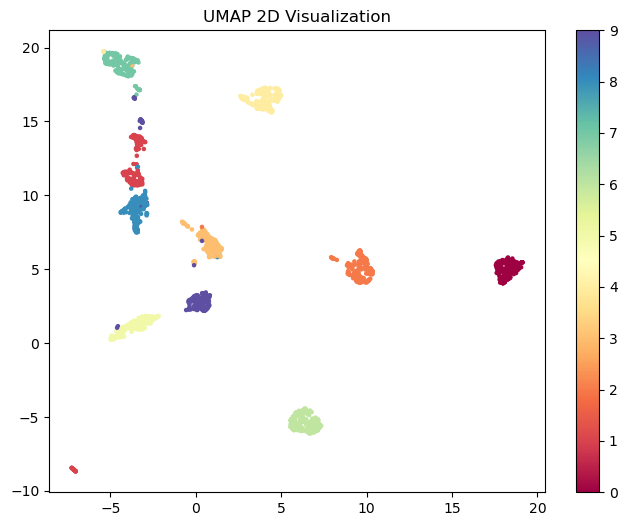

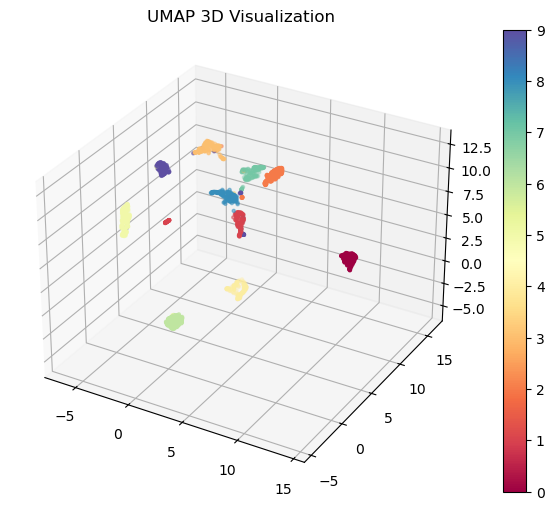

CPU times: user 31.8 s, sys: 252 ms, total: 32.1 s
Wall time: 25.1 s


In [5]:
%%time

from umap import UMAP
import matplotlib.pyplot as plt
from sklearn.datasets import load_digits

# Load example data (handwritten digits dataset)
data, labels = load_digits(return_X_y=True)

# UMAP for 2D visualization
umap_2d = UMAP(n_neighbors=15, min_dist=0.1, n_components=2)
embedding_2d = umap_2d.fit_transform(data)

# UMAP for 3D visualization
umap_3d = UMAP(n_neighbors=15, min_dist=0.1, n_components=3)
embedding_3d = umap_3d.fit_transform(data)

# Plot 2D embedding
plt.figure(figsize=(8, 6))
plt.scatter(embedding_2d[:, 0], embedding_2d[:, 1], c=labels, cmap='Spectral', s=5)
plt.colorbar()
plt.title("UMAP 2D Visualization")
plt.show()

# Plot 3D embedding
fig = plt.figure(figsize=(8, 6))
ax = fig.add_subplot(111, projection='3d')
scatter = ax.scatter(embedding_3d[:, 0], embedding_3d[:, 1], embedding_3d[:, 2], c=labels, cmap='Spectral', s=5)
plt.colorbar(scatter)
plt.title("UMAP 3D Visualization")
plt.show()

## GPU UMAP

[2025-08-18 03:49:54.212] [CUML] [info] cuML: Installed accelerator for sklearn.
[2025-08-18 03:49:54.214] [CUML] [info] cuML: Installed accelerator for umap.
[2025-08-18 03:49:54.234] [CUML] [info] cuML: Installed accelerator for hdbscan.
[2025-08-18 03:49:54.234] [CUML] [info] cuML: Successfully initialized accelerator.
[2025-08-18 03:49:54.300] [CUML] [info] Building knn graph using brute force
[2025-08-18 03:49:57.815] [CUML] [info] Building knn graph using brute force


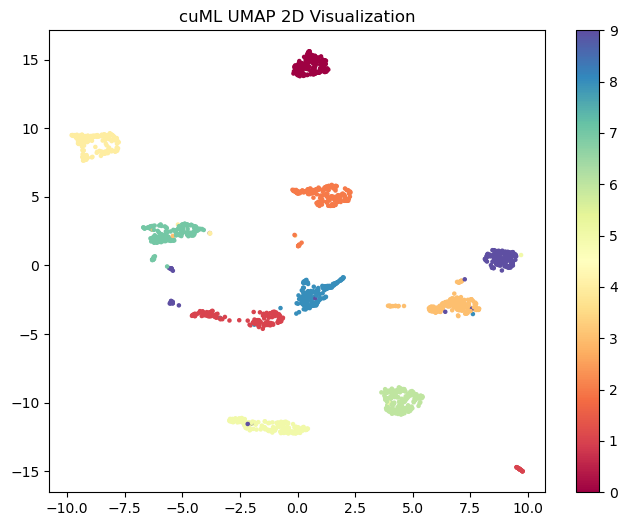

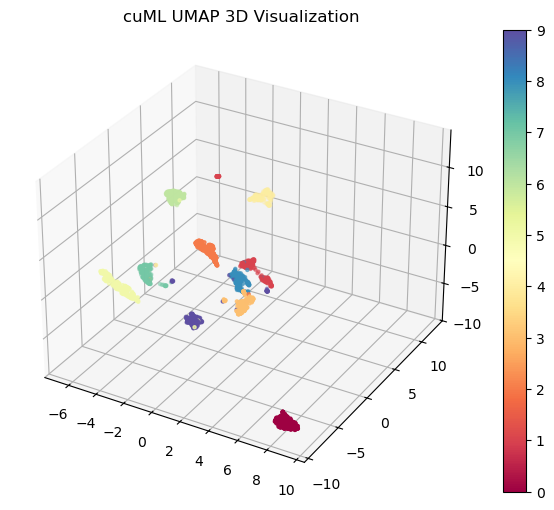

CPU times: user 2.74 s, sys: 396 ms, total: 3.14 s
Wall time: 9.84 s


In [6]:
%%time
%load_ext cuml.accel

from umap import UMAP
import matplotlib.pyplot as plt
from sklearn.datasets import load_digits

# Load example data (handwritten digits dataset)
data, labels = load_digits(return_X_y=True)

# cuML UMAP for 2D visualization
umap_2d = UMAP(n_neighbors=15, min_dist=0.1, n_components=2)
embedding_2d = umap_2d.fit_transform(data)

# cuML UMAP for 3D visualization
umap_3d = UMAP(n_neighbors=15, min_dist=0.1, n_components=3)
embedding_3d = umap_3d.fit_transform(data)

# Plot 2D embedding
plt.figure(figsize=(8, 6))
plt.scatter(embedding_2d[:, 0], embedding_2d[:, 1], c=labels, cmap='Spectral', s=5)
plt.colorbar()
plt.title("cuML UMAP 2D Visualization")
plt.show()

# Plot 3D embedding
fig = plt.figure(figsize=(8, 6))
ax = fig.add_subplot(111, projection='3d')
scatter = ax.scatter(embedding_3d[:, 0], embedding_3d[:, 1], embedding_3d[:, 2], c=labels, cmap='Spectral', s=5)
plt.colorbar(scatter)
ax.set_title("cuML UMAP 3D Visualization")
plt.show()

**Well Done!** Let's move to the [next notebook](02_K-Means.ipynb). 

<img src="images/nvidia_header.png" style="margin-left: -30px; width: 300px; float: left;">